# Descriptive Statistics

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
os.chdir('/home/adam/personal/msc/thesis/Data and code')

from adamthesis.data_loading import DatasetLoader, slim_down_features

batch1_df = DatasetLoader().use_batch1_individual_data_csv().use_all_features().get_dataframe()
batch2_df = DatasetLoader().use_batch2_individual_data_csv().use_all_features().get_dataframe()
batch2_df = slim_down_features(batch1_df, batch2_df) # Only considering features present in batch 1

from scipy.stats import ttest_ind
vars_list = []
for col in batch1_df.columns:
    if col not in ['Team ID', 'student Id']:
        t_stat, p_val = ttest_ind(batch1_df[col], batch2_df[col], equal_var=False)
        vars_list.append({'Feature': col, 'Batch 1 Mean': batch1_df[col].mean(), 'Batch 2 Mean': batch2_df[col].mean(), 'T-statistic': t_stat, 'P-value': p_val})

print("Features with significant differences between batches in terms of T-test (p <= 0.05):")

pd.DataFrame(vars_list).set_index('Feature').sort_values('P-value').query('`P-value` <= 0.05')


Features with significant differences between batches in terms of T-test (p <= 0.05):


/home/adam/personal/msc/thesis/Data and code/.venv/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


,Batch 1 Mean,Batch 2 Mean,T-statistic,P-value
Feature,,,,
351_Semester,4.48,2.36,9.500336,1.471888e-15
514_Relevancy,0.62,0.00,8.941329,7.211931e-12
242_Semester,4.04,1.86,6.337026,7.435599e-09
462_Relevancy,0.78,0.28,5.729243,1.125263e-07
443_Semester,2.50,0.62,5.702583,1.340779e-07
352_Relevancy,0.62,0.16,5.293647,8.224059e-07
438,1.34,-0.90,3.763928,4.277366e-04
445_Relevancy,0.54,0.24,3.199495,1.867449e-03
371,0.62,-1.00,3.026896,3.931406e-03


# Visual Comparison of significantly different features

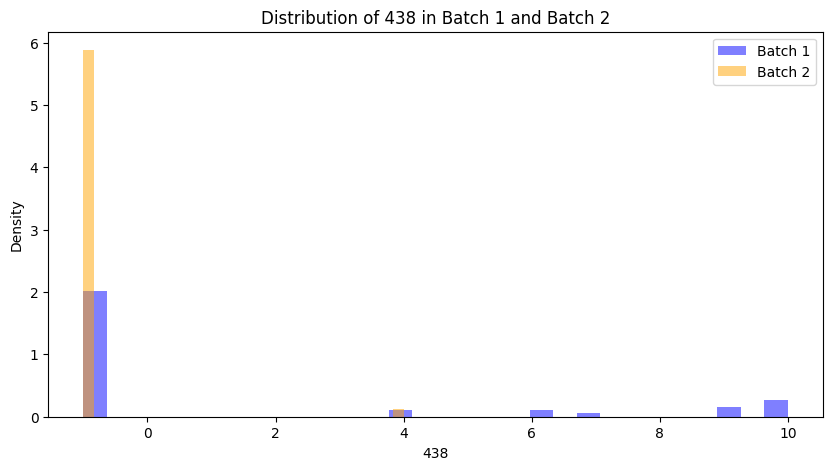

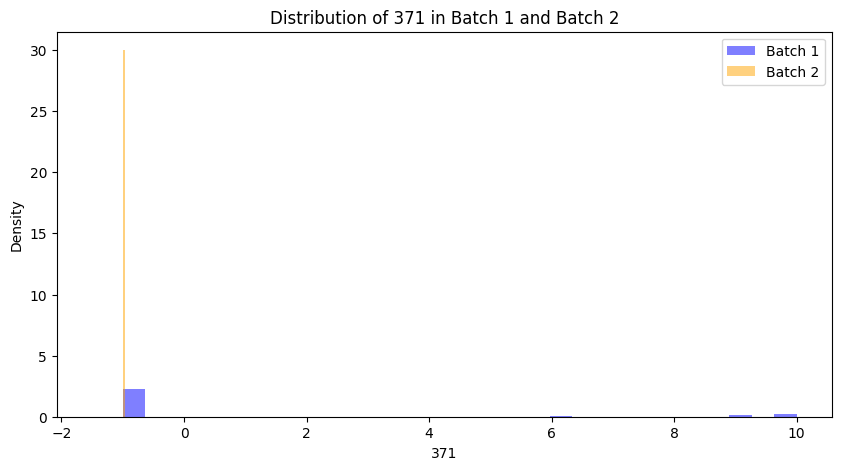

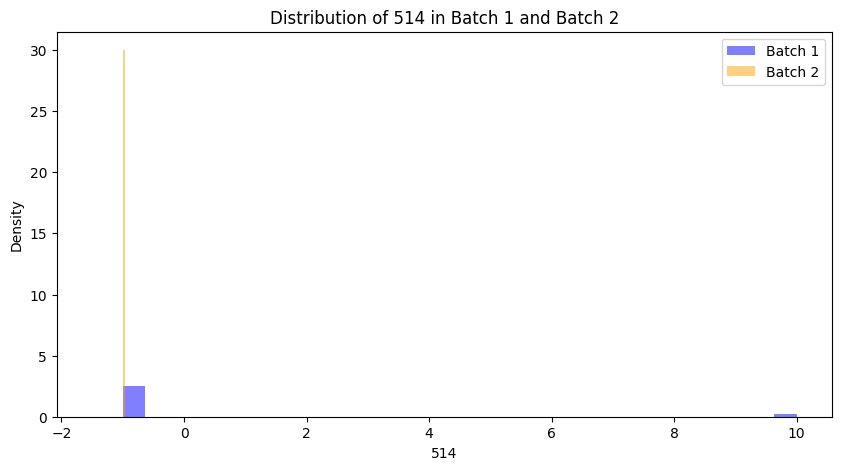

In [3]:
significant_features = ['438', '371', '514']
for feature in significant_features:
    plt.figure(figsize=(10, 5))
    plt.hist(batch1_df[feature], bins=30, alpha=0.5, label='Batch 1', color='blue', density=True)
    plt.hist(batch2_df[feature], bins=30, alpha=0.5, label='Batch 2', color='orange', density=True)
    plt.title(f'Distribution of {feature} in Batch 1 and Batch 2')
    plt.xlabel(feature)
    plt.ylabel('Density')
    plt.legend()
    plt.show()